In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv("/content/drive/MyDrive/DA/archive (2)/kc_house_data.csv")

In [5]:
df.describe()

,id,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
count,2.161300e+04,2.161300e+04,21613.000000,21613.000000,21613.000000,2.161300e+04,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000
mean,4.580302e+09,5.400881e+05,3.370842,2.114757,2079.899736,1.510697e+04,1.494309,0.007542,0.234303,3.409430,7.656873,1788.390691,291.509045,1971.005136,84.402258,98077.939805,47.560053,-122.213896,1986.552492,12768.455652
std,2.876566e+09,3.671272e+05,0.930062,0.770163,918.440897,4.142051e+04,0.539989,0.086517,0.766318,0.650743,1.175459,828.090978,442.575043,29.373411,401.679240,53.505026,0.138564,0.140828,685.391304,27304.179631
min,1.000102e+06,7.500000e+04,0.000000,0.000000,290.000000,5.200000e+02,1.000000,0.000000,0.000000,1.000000,1.000000,290.000000,0.000000,1900.000000,0.000000,98001.000000,47.155900,-122.519000,399.000000,651.000000
25%,2.123049e+09,3.219500e+05,3.000000,1.750000,1427.000000,5.040000e+03,1.000000,0.000000,0.000000,3.000000,7.000000,1190.000000,0.000000,1951.000000,0.000000,98033.000000,47.471000,-122.328000,1490.000000,5100.000000
50%,3.904930e+09,4.500000e+05,3.000000,2.250000,1910.000000,7.618000e+03,1.500000,0.000000,0.000000,3.000000,7.000000,1560.000000,0.000000,1975.000000,0.000000,98065.000000,47.571800,-122.230000,1840.000000,7620.000000
75%,7.308900e+09,6.450000e+05,4.000000,2.500000,2550.000000,1.068800e+04,2.000000,0.000000,0.000000,4.000000,8.000000,2210.000000,560.000000,1997.000000,0.000000,98118.000000,47.678000,-122.125000,2360.000000,10083.000000
max,9.900000e+09,7.700000e+06,33.000000,8.000000,13540.000000,1.651359e+06,3.500000,1.000000,4.000000,5.000000,13.000000,9410.000000,4820.000000,2015.000000,2015.000000,98199.000000,47.777600,-121.315000,6210.000000,871200.000000


In [6]:
df.shape

(21613, 21)

In [7]:
df.columns

Index(['id', 'date', 'price', 'bedrooms', 'bathrooms', 'sqft_living',
       'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade',
       'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode',
       'lat', 'long', 'sqft_living15', 'sqft_lot15'],
      dtype='object')

In [8]:
df.isnull().sum()

,0
id,0
date,0
price,0
bedrooms,0
bathrooms,0
sqft_living,0
sqft_lot,0
floors,0
waterfront,0
view,0


In [9]:
df = df.drop_duplicates()

In [11]:
room_cols = ["bedrooms", "bathrooms"]
for col in room_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")
    df.loc[df[col] <= 0, col] = np.nan
    df[col] = df[col].fillna(df[col].median())

In [12]:
df["date"] = pd.to_datetime(df["date"], errors="coerce")

In [13]:
for col in ["yr_built", "yr_renovated"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

In [14]:
df["sale_year"] = df["date"].dt.year
df["house_age"] = df["sale_year"] - df["yr_built"]

In [15]:
df["years_since_renovation"] = np.where(
    df["yr_renovated"].notna() & (df["yr_renovated"] > 0),
    df["sale_year"] - df["yr_renovated"],
    np.nan
)

In [16]:
df.loc[df["house_age"] < 0, "house_age"] = np.nan
df.loc[df["years_since_renovation"] < 0,
       "years_since_renovation"] = np.nan


In [17]:
df["price_per_sqft_living"] = np.where(
    df["sqft_living"] > 0,
    df["price"] / df["sqft_living"],
    np.nan
)

In [18]:
df["price_per_sqft_lot"] = np.where(
    df["sqft_lot"] > 0,
    df["price"] / df["sqft_lot"],
    np.nan
)

In [19]:
Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)
IQR = Q3 - Q1

In [20]:
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

In [21]:
df["valuation_outlier"] = (
    (df["price"] < lower_bound) |
    (df["price"] > upper_bound)
)

In [22]:
print("\nPrice statistical bounds:")
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Outliers:", df["valuation_outlier"].sum())


Price statistical bounds:
Lower bound: -162625.0
Upper bound: 1129575.0
Outliers: 1146


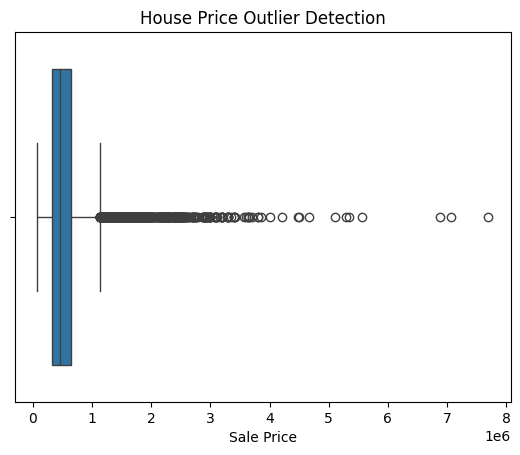

In [23]:
sns.boxplot(x=df["price"])
plt.title("House Price Outlier Detection")
plt.xlabel("Sale Price")
plt.show()

In [24]:
print(df[df["valuation_outlier"]][
    ["price", "sqft_living", "sqft_lot",
     "price_per_sqft_living", "price_per_sqft_lot"]
])

           price  sqft_living  sqft_lot  price_per_sqft_living  \
5      1225000.0         5420    101930             226.014760   
21     2000000.0         3050     44867             655.737705   
49     1350000.0         2753     65005             490.374137   
69     1325000.0         3200     20158             414.062500   
125    1450000.0         2750     17789             527.272727   
...          ...          ...       ...                    ...   
21568  1700000.0         3830      8963             443.864230   
21576  3567000.0         4850     10584             735.463918   
21590  1222500.0         4910      9444             248.981670   
21597  1575000.0         3410     10125             461.876833   
21600  1537000.0         4470      8088             343.847875   

       price_per_sqft_lot  
5               12.018052  
21              44.576192  
49              20.767633  
69              65.730727  
125             81.511046  
...                   ...  
21568      

In [25]:
df.to_csv("cleaned_house_sales.csv", index=False)

In [26]:
print("\nCleaned dataset saved successfully.")
print(df.head())


Cleaned dataset saved successfully.
           id       date     price  bedrooms  bathrooms  sqft_living  \
0  7129300520 2014-10-13  221900.0       3.0       1.00         1180   
1  6414100192 2014-12-09  538000.0       3.0       2.25         2570   
2  5631500400 2015-02-25  180000.0       2.0       1.00          770   
3  2487200875 2014-12-09  604000.0       4.0       3.00         1960   
4  1954400510 2015-02-18  510000.0       3.0       2.00         1680   

   sqft_lot  floors  waterfront  view  ...      lat     long  sqft_living15  \
0      5650     1.0           0     0  ...  47.5112 -122.257           1340   
1      7242     2.0           0     0  ...  47.7210 -122.319           1690   
2     10000     1.0           0     0  ...  47.7379 -122.233           2720   
3      5000     1.0           0     0  ...  47.5208 -122.393           1360   
4      8080     1.0           0     0  ...  47.6168 -122.045           1800   

   sqft_lot15  sale_year  house_age  years_since_renova